### Part A – Data Quality & Basic Insights

In [99]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the original dataset
df = pd.read_csv("sales_raw.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [101]:
# Display first five rows
print("First Five Rows:")
display(df.head())

# Display dataset shape
print("\nDataset Shape:")
print(df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isna().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

First Five Rows:


,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,10/1/2026,North,food,2.0,120
1,1002,10/1/2026,South,Books,1.0,250
2,1003,10/2/2026,North,Food,3.0,110
3,1004,10/2/2026,East,Stationery,4.0,50
4,1005,10/3/2026,SOUTH,books,2.0,250



Dataset Shape:
(21, 6)

Column Names:
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']

Data Types:
transaction_id      int64
sale_date             str
region                str
category              str
quantity          float64
unit_price            str
dtype: object

Missing Values:
transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64

Duplicate Rows:
1


In [102]:
# Make a copy so the original file stays unchanged
cleaned_df = df.copy()

# Count original rows
before_cleaning = len(cleaned_df)

print("Rows before cleaning:", before_cleaning)

Rows before cleaning: 21


In [103]:
# Remove extra spaces and standardize text
cleaned_df["region"] = cleaned_df["region"].str.strip().str.title()

cleaned_df["category"] = cleaned_df["category"].str.strip().str.title()

print(cleaned_df[["region", "category"]].head(10))

  region    category
0  North        Food
1  South       Books
2  North        Food
3   East  Stationery
4  South       Books
5   West        Food
6  North  Stationery
7   East       Books
8   West        Food
9  South  Stationery


In [104]:
# Remove duplicate rows
cleaned_df = cleaned_df.drop_duplicates()

print("Duplicate rows removed.")
print("Rows after removing duplicates:", len(cleaned_df))

Duplicate rows removed.
Rows after removing duplicates: 20


In [105]:
# Convert sale_date into datetime format
cleaned_df["sale_date"] = pd.to_datetime(
    cleaned_df["sale_date"],
    errors="coerce"
)

# Remove rows with invalid dates
cleaned_df = cleaned_df.dropna(subset=["sale_date"])

print("Invalid dates handled.")

Invalid dates handled.


In [106]:
# Convert unit_price into numeric format
cleaned_df["unit_price"] = pd.to_numeric(
    cleaned_df["unit_price"],
    errors="coerce"
)

# Treat negative, zero and unusually high prices as invalid
cleaned_df.loc[
    (cleaned_df["unit_price"] <= 0) |
    (cleaned_df["unit_price"] > 1000),
    "unit_price"
] = None

print("Invalid prices identified.")

Invalid prices identified.


In [107]:
# Remove rows with negative quantity
cleaned_df = cleaned_df[
    cleaned_df["quantity"].isna() |
    (cleaned_df["quantity"] >= 0)
]

# Remove rows where region or category is missing
cleaned_df = cleaned_df.dropna(
    subset=["region", "category"]
)

print("Invalid quantities handled.")

Invalid quantities handled.


In [108]:
# Fill missing values using category median
for category in cleaned_df["category"].unique():

    category_rows = cleaned_df["category"] == category

    # Fill missing quantity
    median_quantity = cleaned_df.loc[
        category_rows, "quantity"
    ].median()

    cleaned_df.loc[
        category_rows, "quantity"
    ] = cleaned_df.loc[
        category_rows, "quantity"
    ].fillna(median_quantity)

    # Fill missing price
    median_price = cleaned_df.loc[
        category_rows, "unit_price"
    ].median()

    cleaned_df.loc[
        category_rows, "unit_price"
    ] = cleaned_df.loc[
        category_rows, "unit_price"
    ].fillna(median_price)

print("Missing values filled successfully")

Missing values filled successfully


In [109]:
print("Missing Values After Cleaning:")
print(cleaned_df.isna().sum())

print("\nDuplicate Rows After Cleaning:")
print(cleaned_df.duplicated().sum())

print("\nCleaned Dataset:")
display(cleaned_df)


Missing Values After Cleaning:
transaction_id    0
sale_date         0
region            0
category          0
quantity          0
unit_price        0
dtype: int64

Duplicate Rows After Cleaning:
0

Cleaned Dataset:


,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,2026-10-01,North,Food,2.0,120.0
1,1002,2026-10-01,South,Books,1.0,250.0
2,1003,2026-10-02,North,Food,3.0,110.0
3,1004,2026-10-02,East,Stationery,4.0,50.0
4,1005,2026-10-03,South,Books,2.0,250.0
5,1006,2026-10-03,West,Food,3.0,130.0
6,1007,2026-10-04,North,Stationery,3.0,60.0
7,1008,2026-10-04,East,Books,1.0,300.0
8,1009,2026-10-05,West,Food,5.0,90.0
9,1010,2026-10-05,South,Stationery,2.0,50.0


In [110]:
# Count rows after cleaning
after_cleaning = len(cleaned_df)

print("Rows before cleaning:", before_cleaning)
print("Rows after cleaning:", after_cleaning)

print("Rows removed:", before_cleaning - after_cleaning)

Rows before cleaning: 21
Rows after cleaning: 17
Rows removed: 4


##Revenue ka formula:
##Revenue = Quantity \times Unit\ Price

In [111]:
# Calculate revenue
cleaned_df["revenue"] = (
    cleaned_df["quantity"] * cleaned_df["unit_price"]
)

print("Revenue Column Added:")
display(cleaned_df.head())

Revenue Column Added:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue
0,1001,2026-10-01,North,Food,2.0,120.0,240.0
1,1002,2026-10-01,South,Books,1.0,250.0,250.0
2,1003,2026-10-02,North,Food,3.0,110.0,330.0
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0
4,1005,2026-10-03,South,Books,2.0,250.0,500.0


In [112]:
# Group revenue by region
region_summary = cleaned_df.groupby("region")["revenue"].sum().reset_index()

region_summary = region_summary.sort_values(
    by="revenue",
    ascending=False
)

print("Revenue Summary by Region:")
display(region_summary)

Revenue Summary by Region:


,region,revenue
1,North,1520.0
2,South,1135.0
0,East,960.0
3,West,920.0


In [113]:
# Group revenue by category
category_summary = cleaned_df.groupby(
    "category"
)["revenue"].sum().reset_index()

category_summary = category_summary.sort_values(
    by="revenue",
    ascending=False
)

print("Revenue Summary by Category:")
display(category_summary)

Revenue Summary by Category:


,category,revenue
1,Food,2555.0
0,Books,1370.0
2,Stationery,610.0


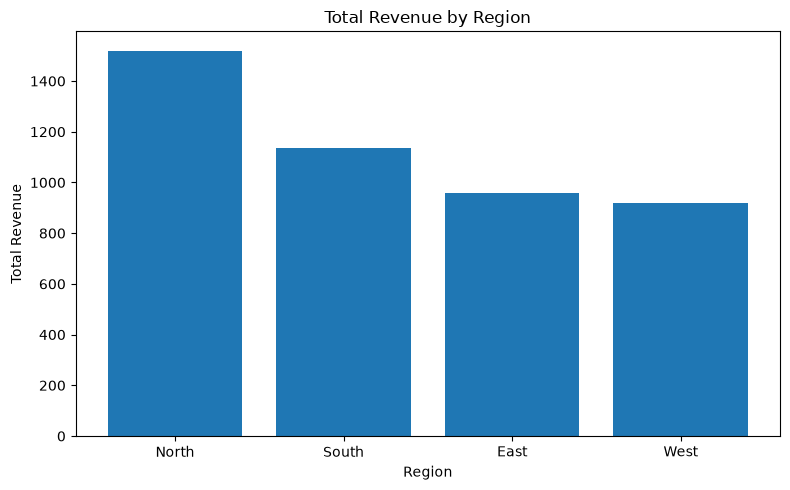

In [114]:
plt.figure(figsize=(8, 5))

plt.bar(
    region_summary["region"],
    region_summary["revenue"]
)

plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")

plt.tight_layout()
plt.show()

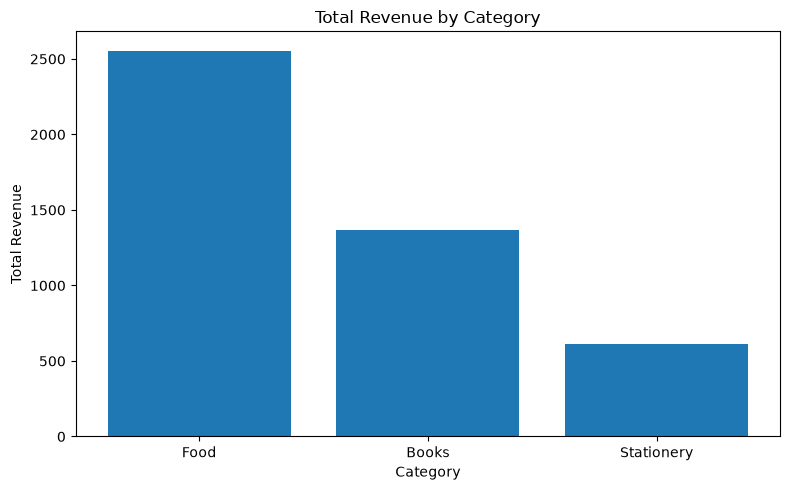

In [115]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_summary["category"],
    category_summary["revenue"]
)

plt.title("Total Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")

plt.tight_layout()
plt.show()

In [116]:
# Find the region with highest revenue
top_region = region_summary.loc[
    region_summary["revenue"].idxmax()
]

# Find the category with highest revenue
top_category = category_summary.loc[
    category_summary["revenue"].idxmax()
]

print("Finding 1:")
print(
    f"{top_region['region']} region generated the highest "
    f"revenue of {top_region['revenue']:.2f}."
)

print("\nFinding 2:")
print(
    f"{top_category['category']} category generated the highest "
    f"revenue of {top_category['revenue']:.2f}."
)

Finding 1:
North region generated the highest revenue of 1520.00.

Finding 2:
Food category generated the highest revenue of 2555.00.


In [117]:
# Save cleaned dataset into a new CSV file
cleaned_df.to_csv(
    "cleaned_sales.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


### Cleaning Decisions

- Removed duplicate records to avoid repeated data.
- Removed rows with invalid dates because they cannot be used reliably.
- Removed rows with negative quantities because sales quantity cannot be negative.
- Removed rows with missing region or category because they are needed for grouping and analysis.
- Converted invalid prices into missing values.
- Filled missing quantity and prices using the median of their category.
- Standardized region and category names by removing extra spaces and using consistent capitalization.

###  Part B – CSV File Handling & Manipulation 

In [118]:
# Load cleaned CSV file
sales_df = pd.read_csv("cleaned_sales.csv")

# Add tax_amount column
sales_df["tax_amount"] = sales_df["revenue"] * 0.05

print("First Five Rows:")
display(sales_df.head())

First Five Rows:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2.0,120.0,240.0,12.0
1,1002,2026-10-01,South,Books,1.0,250.0,250.0,12.5
2,1003,2026-10-02,North,Food,3.0,110.0,330.0,16.5
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,10.0
4,1005,2026-10-03,South,Books,2.0,250.0,500.0,25.0


In [119]:
# Increase unit_price of Books by 10%
sales_df.loc[
    sales_df["category"] == "Books",
    "unit_price"
] *= 1.10

# Recalculate revenue after price update
sales_df["revenue"] = (
    sales_df["quantity"] * sales_df["unit_price"]
)

# Recalculate tax_amount
sales_df["tax_amount"] = sales_df["revenue"] * 0.05

print("Books prices updated successfully!")

display(
    sales_df[sales_df["category"] == "Books"]
)

Books prices updated successfully!


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
1,1002,2026-10-01,South,Books,1.0,275.0,275.0,13.75
4,1005,2026-10-03,South,Books,2.0,275.0,550.0,27.50
7,1008,2026-10-04,East,Books,1.0,330.0,330.0,16.50
11,1012,2026-10-06,North,Books,1.0,352.0,352.0,17.60


In [120]:
# Remove transaction with ID 1002
sales_df = sales_df[
    sales_df["transaction_id"] != 1002
]

print("Transaction ID 1002 removed successfully!")

display(sales_df.head())

Transaction ID 1002 removed successfully!


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2.0,120.0,240.0,12.0
2,1003,2026-10-02,North,Food,3.0,110.0,330.0,16.5
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,10.0
4,1005,2026-10-03,South,Books,2.0,275.0,550.0,27.5
5,1006,2026-10-03,West,Food,3.0,130.0,390.0,19.5


In [121]:
# Create temporary review_status column
sales_df["review_status"] = "Pending"

print("Temporary Column Added:")
display(sales_df.head())

# Remove temporary column
sales_df = sales_df.drop(
    columns=["review_status"]
)

print("Temporary review_status column removed.")

Temporary Column Added:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount,review_status
0,1001,2026-10-01,North,Food,2.0,120.0,240.0,12.0,Pending
2,1003,2026-10-02,North,Food,3.0,110.0,330.0,16.5,Pending
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,10.0,Pending
4,1005,2026-10-03,South,Books,2.0,275.0,550.0,27.5,Pending
5,1006,2026-10-03,West,Food,3.0,130.0,390.0,19.5,Pending


Temporary review_status column removed.


In [122]:
# Save updated dataset
sales_df.to_csv(
    "sales_updated.csv",
    index=False
)

print("Updated dataset saved successfully!")

Updated dataset saved successfully!


In [123]:
# Read the updated CSV file
verified_df = pd.read_csv("sales_updated.csv")

# Display first five rows
print("First Five Rows")
display(verified_df.head())

# Display final column names
print("\nFinal Column Names:")
print(verified_df.columns.tolist())

# Verify removed transaction
print("\nTransaction ID 1002 Exists?")
print(verified_df["transaction_id"].eq(1002).any())

First Five Rows


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2.0,120.0,240.0,12.0
1,1003,2026-10-02,North,Food,3.0,110.0,330.0,16.5
2,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,10.0
3,1005,2026-10-03,South,Books,2.0,275.0,550.0,27.5
4,1006,2026-10-03,West,Food,3.0,130.0,390.0,19.5



Final Column Names:
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']

Transaction ID 1002 Exists?
False
